# Deep Learning based Forecasting

**In this notebook**

1. [Deep learning in `sktime`](#dl-in-sktime) - which models are there, and how do you use them?
2. [Pretraining](#pretraining) - how can a network learn from *other* series, e.g., to forecast a new product with little history?
3. [Conclusions](#conclusions) - what we learnt, and the bridge to foundation models (next notebook)

**Setup**

In [1]:
import warnings

warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import torch

# Set seed for reproducibility
torch.manual_seed(42)
torch.use_deterministic_algorithms(True, warn_only=True)
np.random.seed(42)

<a id="dl-in-sktime"></a>
## 1. Deep learning in `sktime`

**Now:** a quick map of the deep learning model generations - then how `sktime` gives you all of them behind one API.

### Generations of deep learning models

| Architecture class          | Examples                                  | Defining feature                           |
|-----------------------------|-------------------------------------------|--------------------------------------------|
| sequence-recurrent networks | vanilla RNN (1986), LSTM (1997)           | sequence processing recurrency             |
| window processors           | NBEATS (2019), NHITS (2022)               | window processing                          |
| Early transformer/attention | Informer, Autoformer (2021)               | transformer, attention mechanism           |
| General purpose pre-trained FM | LagLlama, TimesFM, Moirai (2024)       | pre-trained, general-purpose, weights ready |
| Current FM                  | 1 per week in your LinkedIn feed          | variations (e.g., proba output) and specializations (e.g., application field), multimodality (text input) |

### Deep learning in `sktime` at a glance

`sktime` has models from all generations, with the same `fit` / `predict` API as for ARIMA or exponential smoothing - swap the model, keep the rest of your code.

| Generation | Example `sktime` estimators | Backend |
|---|---|---|
| recurrent | `NeuralForecastLSTM`, `NeuralForecastGRU`, `PytorchForecastingDeepAR`, `ESRNNForecaster` | `neuralforecast`, `pytorch-forecasting`, native PyTorch |
| window processors | `PytorchForecastingNBeats`, `PytorchForecastingNHiTS`, `LTSFLinearForecaster`, `LTSFDLinearForecaster` | `pytorch-forecasting`, native PyTorch |
| attention / transformer | `PytorchForecastingTFT`, `LTSFTransformerForecaster` | `pytorch-forecasting`, native PyTorch |
| pre-trained foundation models | `ChronosForecaster`, `TimesFM3Forecaster`, `TinyTimeMixerForecaster`, ... | next notebook |

**What `sktime` adds on top of the raw models:**

* **global / panel training** - pass a panel or hierarchical `y` to `fit`, one network learns across all series
* **pretraining** - `pretrain` on *other* series, then `fit` on yours (see below)
* **probabilistic forecasts** - e.g., DeepAR, NHiTS, TFT support `predict_interval` / `predict_quantiles`
* **exogenous data** - `X` in `fit` / `predict`, same as for classical models
* **composition** - pipelines, tuning, ensembling and benchmarking work for DL models too
* **persistence** - `save` a trained forecaster, restore it with `sktime.base.load`

**How it works:** you pass data, `sktime` builds the dataset, the network and the training loop.

<img src="./imgs/dl_in_sktime.png" alt="Deep learning in sktime: you pass data, sktime does the plumbing" style="width: 100%; max-width: 1200px;">

### `pytorch-forecasting` under the hood

Zooming into one backend: the steps from the diagram, for `pytorch-forecasting`.

`pytorch-forecasting` is the idiomatic DL forecasting package that `sktime` uses for native, performant deep learning models
(maintained in the `sktime` ecosystem: [sktime/pytorch-forecasting](https://github.com/sktime/pytorch-forecasting)).

* `pytorch-forecasting` uses `lightning` (https://lightning.ai/) to orchestrate training
    * no hand-written `optimizer.step()`, `loss.backward()`, `optimizer.zero_grad()`
    * moving training to GPU / multiple GPUs, checkpointing, callbacks (e.g., to log losses and gradient norms)
* in `sktime`, a ptf model is configured with three dictionaries:

```python
from sktime.forecasting.pytorchforecasting import PytorchForecastingNBeats

forecaster = PytorchForecastingNBeats(
    model_params={"context_length": 24, "learning_rate": 1e-3},  # the network
    dataset_params={"max_encoder_length": 24},                   # ptf TimeSeriesDataSet
    trainer_params={"max_epochs": 20},                           # lightning Trainer
)
forecaster.fit(y_train, fh=range(1, 7))
y_pred = forecaster.predict()
```

* more granular control: train with `pytorch-forecasting` / `torch` directly, then use the weights via the `sktime` API

Best practice (as for any model): **start simple, overfit a single batch first, and always compare against simple baselines.**

**Finding deep learning models** - every estimator carries searchable *tags*, e.g., the `category` tag:

In [2]:
from sktime.registry import all_estimators

all_estimators(
    "forecaster",
    filter_tags={"category": "deep_learning"},
    as_dataframe=True,
)

W1121 09:03:45.699000 2037 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


,name,object
0,AuroraForecaster,<class 'sktime.forecasting.aurora.AuroraForeca...
1,CINNForecaster,<class 'sktime.forecasting.cinn.CINNForecaster'>
2,Chronos2Forecaster,<class 'sktime.forecasting.chronos2.Chronos2Fo...
3,ChronosForecaster,<class 'sktime.forecasting.chronos.ChronosFore...
4,CiscoTSMForecaster,<class 'sktime.forecasting.cisco_tsm.CiscoTSMF...
5,ConvTimeNetForecaster,<class 'sktime.forecasting.convtimenet.ConvTim...
6,ESRNNForecaster,<class 'sktime.forecasting.es_rnn.ESRNNForecas...
7,FalconTSTForecaster,<class 'sktime.forecasting.falcon_tst.FalconTS...
8,FalconXForecaster,<class 'sktime.forecasting.falcon_x.FalconXFor...
9,FlowStateForecaster,<class 'sktime.forecasting.flowstate.FlowState...


Or check out the [model marketplace at sktime.net](https://www.sktime.net/models/)!

<img src="./imgs/sktime-models.png" alt="sktime model marketplace" style="width: 100%; max-width: 1200px;">

**What we learnt so far**

* deep learning models from all generations, behind the same `fit` / `predict` API
* you pass `y`, `X` and `fh` - `sktime` builds the dataset, the network and the training loop
* find models via tags (`all_estimators`) or the model marketplace

**Next:** pretraining - letting a network learn from *other* time series.

<a id="pretraining"></a>
## 2. Pretraining in `sktime`

**Now:** a network needs a lot of data, but a single (new) series often has little.
`pretrain` lets it learn from *other, related* series first - one API for all pretrainable models.

<img src="./imgs/global-fcst.png" alt="Global Forecast" style="width: 100%; max-width: 600px;">

| Approach | Use when |
|---|---|
| `fit` only | single series, or collection of (hierarchical, multivariate) to forecast |
| `pretrain` + `fit` | "global", cross-learning. Pretrain on other series, forecast some |

`pretrain` API lets you train on **your own domain data** as examples

### Estimator state lifecycle

Every sktime forecaster tracks its lifecycle phase via the `state` property.
Pretraining introduces an intermediate state between construction and fitting:

```
             pretrain()              fit()             predict()
   "new" ──────────────> "pretrained" ──────> "fitted" ──────────> ...
     │                                           ^
     └───────────────── fit() ───────────────────┘
```

- Calling `fit` on a `"new"` forecaster resets and trains from scratch (the standard workflow).
- Calling `fit` on a `"pretrained"` forecaster preserves pretrained weights and fine-tunes.

useful to:

* learn from similar time series
* forecast "cold start" time series, e.g., new products, SKU

#### Example: cold start with `LTSFDLinearForecaster`

* synthetic monthly tourism trips: 28 series (travel purpose x state)
* pretend the 7 **Business** series are *new*: only 30 months of history
* pretrain on the 21 related series (Holiday, Visiting, Other), then `fit` on a new series
* split with `temporal_train_test_split` first, and pretrain on the training part only

**Steps:** split → pretrain on related series → fit and forecast one new series → repeat on all new series, against simple baselines

In [3]:
from sktime.split import temporal_train_test_split

df = pd.read_csv("data/monthly_tourism_synthetic.csv")
df["Month"] = pd.PeriodIndex(df["Month"], freq="M")
y = df.groupby(["Purpose", "State", "Month"])[["Trips"]].sum()

y_train, y_test = temporal_train_test_split(y, test_size=6)

y_related = y_train.drop(index="Business", level="Purpose")
y_new_train = y_train.loc["Business"].groupby(level="State").tail(30)
y_new_test = y_test.loc["Business"]

In [4]:
from sktime.forecasting.ltsf import LTSFDLinearForecaster

fh = [1, 2, 3, 4, 5, 6]
dlinear_params = dict(seq_len=24, pred_len=6, num_epochs=50, batch_size=16, lr=1e-3)

forecaster = LTSFDLinearForecaster(**dlinear_params)
forecaster.pretrain(y_related)
forecaster.state

'pretrained'

Fit on one new series and forecast - and, for comparison, the same network fitted without pretraining.

In [5]:
state = "Victoria"

forecaster.fit(y_new_train.loc[state], fh=fh)
y_pred_pretrained = forecaster.predict()

fit_only = LTSFDLinearForecaster(**dlinear_params)
fit_only.fit(y_new_train.loc[state], fh=fh)
y_pred_fit_only = fit_only.predict()

forecaster.state, fit_only.state

('fitted', 'fitted')

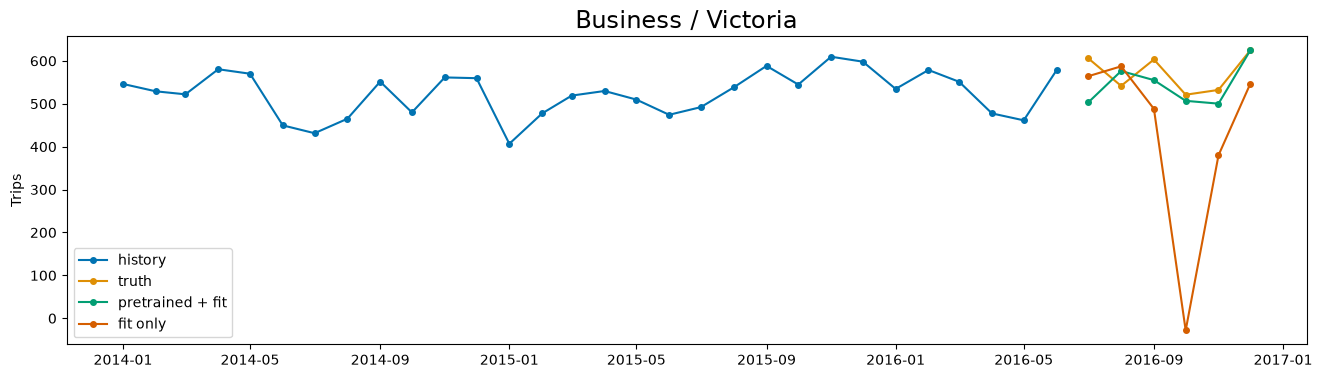

In [6]:
from sktime.utils.plotting import plot_series

plot_series(
    y_new_train.loc[state],
    y_new_test.loc[state],
    y_pred_pretrained,
    y_pred_fit_only,
    labels=["history", "truth", "pretrained + fit", "fit only"],
    title=f"Business / {state}",
);

A single series and a single seed can be lucky. Below we repeat the experiment
on all 7 new series with 3 seeds, and add two simple baselines: seasonal naive (repeat last year) and seasonal mean.

In [7]:
import copy

from sktime.forecasting.naive import NaiveForecaster
from sktime.performance_metrics.forecasting import mean_absolute_error

rows = []
for seed in [0, 1, 2]:
    torch.manual_seed(seed)
    pretrained = LTSFDLinearForecaster(**dlinear_params).pretrain(y_related)

    for state in y_new_train.index.unique(level="State"):
        torch.manual_seed(seed)
        models = {
            "Fit only": LTSFDLinearForecaster(**dlinear_params),
            "Pretrained + fit": copy.deepcopy(pretrained),
            "Seasonal naive": NaiveForecaster(strategy="last", sp=12),
            "Seasonal mean": NaiveForecaster(strategy="mean", sp=12),
        }
        for name, model in models.items():
            y_pred = model.fit(y_new_train.loc[state], fh=fh).predict()
            mae = mean_absolute_error(y_new_test.loc[state], y_pred)
            rows.append({"state": state, "seed": seed, "model": name, "MAE": mae})

results = pd.DataFrame(rows)
results.pivot_table(index="state", columns="model", values="MAE").round(1)

model,Fit only,Pretrained + fit,Seasonal mean,Seasonal naive
state,,,,
ACT,274.2,75.5,72.0,114.5
New South Wales,571.5,236.2,254.0,261.8
Northern Territory,86.1,29.3,29.7,36.6
Queensland,382.3,89.3,98.7,115.3
South Australia,89.3,23.4,29.2,32.0
Victoria,213.0,35.6,54.2,43.2
Western Australia,169.6,48.5,32.3,43.1


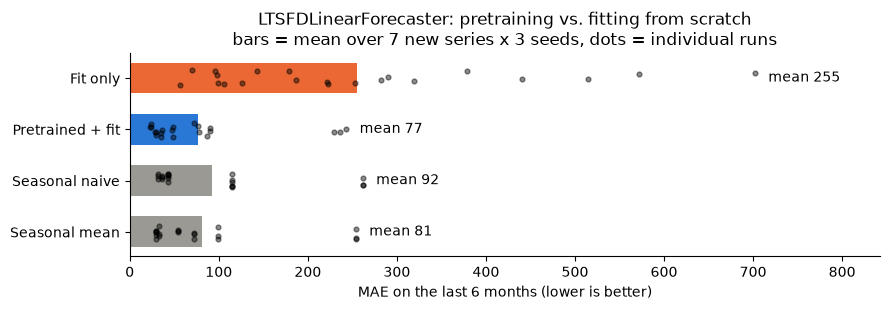

In [8]:
import matplotlib.pyplot as plt

order = ["Fit only", "Pretrained + fit", "Seasonal naive", "Seasonal mean"]
colors = {
    "Fit only": "#eb6834",
    "Pretrained + fit": "#2a78d6",
    "Seasonal naive": "#9a9993",
    "Seasonal mean": "#9a9993",
}
mean_mae = results.groupby("model")["MAE"].mean().reindex(order)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(order, mean_mae.values, color=[colors[m] for m in order], height=0.6)

rng = np.random.default_rng(0)
for i, model in enumerate(order):
    runs = results.loc[results["model"] == model, "MAE"]
    jitter = rng.uniform(-0.15, 0.15, len(runs))
    ax.scatter(runs, i + jitter, color="black", s=12, alpha=0.45, zorder=3)
    ax.text(max(runs.max(), mean_mae[model]) + 15, i, f"mean {mean_mae[model]:.0f}",
            va="center")

ax.set_xlim(0, results["MAE"].max() * 1.2)  # room for the labels
ax.invert_yaxis()
ax.set_xlabel("MAE on the last 6 months (lower is better)")
ax.set_title("LTSFDLinearForecaster: pretraining vs. fitting from scratch\n"
             "bars = mean over 7 new series x 3 seeds, dots = individual runs")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What we learnt from the example:**

* cold start: with only 30 months of history, the network alone has too little data (fit only: mean MAE 255)
* pretraining on *related* series brings the same network down to 77 - better than fit only for every series and seed
* pretrained + fit also beats seasonal naive (92) and seasonal mean (81) on average, but not on every series: **always benchmark against simple baselines**
* pretraining matters most for short histories - with longer history, fitting alone catches up

### Discovering pretrainable forecasters

**Next:** which other models can be pretrained, and what is new in the API.

Search for the `capability:pretrain` tag. Use `all_estimators` to list them.

In [9]:
from sktime.registry import all_estimators
all_estimators(
    "forecaster",
    filter_tags="capability:pretrain",
    as_dataframe=True,
)

,name,object
0,CINNForecaster,<class 'sktime.forecasting.cinn.CINNForecaster'>
1,ConvTimeNetForecaster,<class 'sktime.forecasting.convtimenet.ConvTim...
2,DummyGlobalForecaster,<class 'sktime.forecasting.dummy_global.DummyG...
3,ESRNNForecaster,<class 'sktime.forecasting.es_rnn.ESRNNForecas...
4,LTSFDLinearForecaster,<class 'sktime.forecasting.ltsf.LTSFDLinearFor...
5,LTSFLinearForecaster,<class 'sktime.forecasting.ltsf.LTSFLinearFore...
6,LTSFNLinearForecaster,<class 'sktime.forecasting.ltsf.LTSFNLinearFor...
7,LTSFTransformerForecaster,<class 'sktime.forecasting.ltsf.LTSFTransforme...
8,LagLlamaForecaster,<class 'sktime.forecasting.lagllama.LagLlamaFo...
9,RBFForecaster,<class 'sktime.forecasting.rbf.RBFForecaster'>


**What's new in pretraining**:

* **more pretrainable models, including foundation models**: `TinyTimeMixerForecaster`, `TimesFM2Forecaster`,
  `TotoForecaster`, `TimeMoEForecaster`, `SundialForecaster`, `LagLlamaForecaster` 
* **global benchmarking**: `evaluate` accepts `cv_global` to pretrain on some series and test on *other* series (1.2)
* **inspect and continue pretraining**: `get_pretrained_params()`; calling `pretrain` again *continues* training on the new batch;
  `reset` wipes the pretrained state
* **`pretrain` beyond forecasting**: classifiers, regressors and detectors now have `pretrain` too (1.3, still experimental)

Example: pretraining in two batches - the second `pretrain` call continues training:

In [10]:
batch_1 = y_related.loc["Holiday"]
batch_2 = y_related.loc["Visiting"]

incremental = LTSFDLinearForecaster(**dlinear_params)
incremental.pretrain(batch_1)
print("after batch 1:", incremental.state, incremental.get_pretrained_params())
incremental.pretrain(batch_2)
print("after batch 2:", incremental.state, incremental.get_pretrained_params())

after batch 1: pretrained {'n_pretrain_instances_': 7}
after batch 2: pretrained {'n_pretrain_instances_': 14}


<a id="conclusions"></a>
## 3. Conclusions - what we learnt

**Deep learning in `sktime`**

* models from all generations: recurrent, window processors, attention, pre-trained
* one consistent `fit` / `predict` API across many packages - `sktime` builds the dataset, network and training loop
* `pytorch-forecasting` as idiomatic DL package under the hood

**Pretraining**

* `pretrain` learns from *other*, related series, then `fit` adapts to yours
* biggest gain for cold start (short history) - and always benchmark against simple baselines
* = how foundation models are obtained (feed much more data ...)

**Next notebook:** foundation models - networks pretrained by a provider on huge data. In `sktime`, the same `pretrain` API fine-tunes them on your data.

### Credits

* Contributors: Srujan Patwardhan ([@srupat](https://github.com/srupat)), Armaghan Shakir ([@geetu040](https://github.com/geetu040)), Franz Kiraly ([@fkiraly](https://github.com/fkiraly))
* Many thanks to [all `sktime` contributors](https://www.sktime.net/en/latest/about/contributors.html)!
